In [2]:
import matplotlib.pyplot as plt

In [3]:
xmin, ymin = 100, 100
xmax, ymax = 400, 300

In [4]:
INSIDE = 0
LEFT = 1
RIGHT = 2
BOTTOM = 4
TOP = 8

def compute_code(x, y):
    code = INSIDE

    if x < xmin:
        code |= LEFT
    elif x > xmax:
        code |= RIGHT

    if y < ymin:
        code |= BOTTOM
    elif y > ymax:
        code |= TOP

    return code

In [5]:
def cohen_sutherland(x1, y1, x2, y2):

    code1 = compute_code(x1, y1)
    code2 = compute_code(x2, y2)

    while True:

        # Completely inside
        if (code1 | code2) == 0:
            return x1, y1, x2, y2

        # Completely outside
        elif (code1 & code2) != 0:
            return None

        # Partially inside
        else:

            if code1 != 0:
                code_out = code1
            else:
                code_out = code2

            if code_out & TOP:
                x = x1 + (x2-x1) * (ymax-y1)/(y2-y1)
                y = ymax

            elif code_out & BOTTOM:
                x = x1 + (x2-x1) * (ymin-y1)/(y2-y1)
                y = ymin

            elif code_out & RIGHT:
                y = y1 + (y2-y1) * (xmax-x1)/(x2-x1)
                x = xmax

            elif code_out & LEFT:
                y = y1 + (y2-y1) * (xmin-x1)/(x2-x1)
                x = xmin

            if code_out == code1:
                x1, y1 = x, y
                code1 = compute_code(x1, y1)
            else:
                x2, y2 = x, y
                code2 = compute_code(x2, y2)

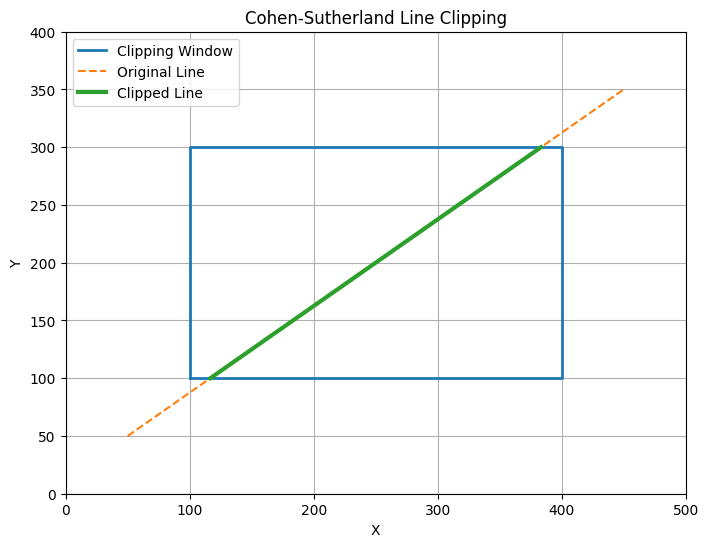

In [7]:
plt.figure(figsize=(8, 6))

# Call the cohen_sutherland function with the line coordinates
result = cohen_sutherland(50, 50, 450, 350)

# Clipping window
plt.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    linewidth=2,
    label="Clipping Window"
)

# Original line
plt.plot(
    [50, 450],
    [50, 350],
    linestyle="--",
    label="Original Line"
)

# Clipped line
if result:
    x1, y1, x2, y2 = result

    plt.plot(
        [x1, x2],
        [y1, y2],
        linewidth=3,
        label="Clipped Line"
    )

plt.xlim(0, 500)
plt.ylim(0, 400)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Cohen-Sutherland Line Clipping")
plt.grid(True)
plt.legend()
plt.show()